# 서울시 개업·폐업 현황 분석 및 다음 분기 폐업 수 예측

## 프로젝트 목적
서울시 자치구·업종별 개업·폐업 현황을 분석하고,
현재 분기의 정보를 이용해 다음 분기 폐업 점포 수를 예측한다.

## 입력 변수(X)
- 전체 점포 수
- 개업 점포 수
- 폐업 점포 수
- 분기

## 예측 대상(y)
- 같은 자치구·업종의 다음 분기 폐업 점포 수

## 진행 순서
1. 데이터 불러오기
2. 탐색적 데이터 분석(EDA)
3. 전처리 및 다음 분기 정답 연결
4. 시간순 학습·검증·테스트 분할
5. 모델 학습 및 검증 성능 비교
6. 최종 모델 테스트 평가
7. 결과 시각화 및 모델 저장

## 1. 데이터 불러오기와 기본 점검

서울 열린데이터광장의 점포·자치구 자료를 사용한다.
출처: https://data.seoul.go.kr/dataList/OA-22173/S/1/datasetView.do

관측 기간은 2021년 1분기~2026년 2분기이며, 한 행은 한 분기·자치구·업종의 집계다. 데이터 크기, 자료형, 결측값과 숫자 범위를 확인한다.

In [48]:
import pandas as pd

df = pd.read_csv(
    "data/seoul_store_district.csv",
    encoding="cp949"
)

df.head()

,기준_년분기_코드,자치구_코드,자치구_코드_명,서비스_업종_코드,서비스_업종_코드_명,전체_점포_수,일반_점포_수,프랜차이즈_점포_수,개업_율,개업_점포_수,폐업_률,폐업_점포_수
0,20262,11740,강동구,CS300043,전자상거래업,749.0,749.0,0.0,0.0,0.0,4.0,30.0
1,20262,11740,강동구,CS300042,주유소,43.0,43.0,0.0,0.0,0.0,0.0,0.0
2,20262,11740,강동구,CS300041,예술품,32.0,32.0,0.0,6.3,2.0,0.0,0.0
3,20262,11740,강동구,CS300040,재생용품 판매점,42.0,42.0,0.0,0.0,0.0,0.0,0.0
4,20262,11740,강동구,CS300039,모터사이클및부품,20.0,20.0,0.0,0.0,0.0,0.0,0.0


In [49]:
print("데이터 크기:", df.shape)

df.info()

데이터 크기: (54765, 12)
<class 'pandas.DataFrame'>
RangeIndex: 54765 entries, 0 to 54764
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   기준_년분기_코드    54765 non-null  int64  
 1   자치구_코드       54765 non-null  int64  
 2   자치구_코드_명     54765 non-null  str    
 3   서비스_업종_코드    54765 non-null  str    
 4   서비스_업종_코드_명  54765 non-null  str    
 5   전체_점포_수      54765 non-null  float64
 6   일반_점포_수      54765 non-null  float64
 7   프랜차이즈_점포_수   54765 non-null  float64
 8   개업_율         54765 non-null  float64
 9   개업_점포_수      54765 non-null  float64
 10  폐업_률         54765 non-null  float64
 11  폐업_점포_수      54765 non-null  float64
dtypes: float64(7), int64(2), str(3)
memory usage: 5.0 MB


In [50]:
columns = [
    "전체_점포_수",
    "개업_점포_수",
    "폐업_점포_수",
    "개업_율",
    "폐업_률"
]

df[columns].describe().T

,count,mean,std,min,25%,50%,75%,max
전체_점포_수,54765.0,257.885967,542.338718,0.0,42.0,119.0,264.0,17802.0
개업_점포_수,54765.0,6.881256,16.318697,0.0,0.0,2.0,7.0,563.0
폐업_점포_수,54765.0,6.731416,15.525332,0.0,0.0,2.0,7.0,496.0
개업_율,54765.0,2.483776,4.020903,0.0,0.0,1.7,3.5,100.0
폐업_률,54765.0,2.420230,3.843196,0.0,0.0,1.8,3.3,200.0


In [51]:
check_columns = [
    "기준_년분기_코드",
    "자치구_코드_명",
    "서비스_업종_코드_명",
    "전체_점포_수",
    "폐업_점포_수",
    "폐업_률"
]

df.loc[df["폐업_률"] > 100, check_columns]


,기준_년분기_코드,자치구_코드_명,서비스_업종_코드_명,전체_점포_수,폐업_점포_수,폐업_률
33028,20231,영등포구,DVD방,1.0,2.0,200.0


In [52]:
df.loc[df["전체_점포_수"] == 0, check_columns]

,기준_년분기_코드,자치구_코드_명,서비스_업종_코드_명,전체_점포_수,폐업_점포_수,폐업_률
10733,20252,금천구,고시원,0.0,0.0,0.0
11490,20252,도봉구,중고가구,0.0,1.0,0.0
24100,20241,강북구,변리사사무소,0.0,1.0,0.0
28972,20233,도봉구,회계사사무소,0.0,1.0,0.0
35015,20224,송파구,DVD방,0.0,1.0,0.0
42377,20221,강동구,DVD방,0.0,1.0,0.0
43274,20221,강서구,DVD방,0.0,1.0,0.0
49321,20213,광진구,한복점,0.0,1.0,0.0
51629,20212,중랑구,DVD방,0.0,1.0,0.0
54616,20211,중구,DVD방,0.0,1.0,0.0


점포 수가 0이거나 폐업률이 100%를 넘는 기록은 자동으로 오류라고 판단하지 않는다. 폐업률의 분모·집계 기준에 주의한다. 최종 예측 대상은 폐업 **건수**이므로 점포 수가 0인 기록도 유지한다.

## 2. 탐색적 데이터 분석(EDA)

폐업률은 규모가 다른 지역·업종의 현황을 비교하는 보조 지표로 사용한다. 분석 결과는 원인이나 개별 가게의 폐업 확률을 뜻하지 않는다.

### 2-1. 마포구 커피·음료 업종의 시기별 변화

In [53]:
df_coffee = df.loc[
    df["서비스_업종_코드_명"] == "커피-음료"
].copy()

print("커피·음료 데이터 크기:", df_coffee.shape)

df_coffee[[
    "기준_년분기_코드",
    "자치구_코드_명",
    "전체_점포_수",
    "폐업_점포_수",
    "폐업_률"
]].head()

커피·음료 데이터 크기: (550, 12)


,기준_년분기_코드,자치구_코드_명,전체_점포_수,폐업_점포_수,폐업_률
90,20262,강동구,944.0,28.0,3.0
190,20262,송파구,1613.0,61.0,3.8
290,20262,강남구,2568.0,87.0,3.4
390,20262,서초구,1554.0,56.0,3.6
490,20262,관악구,908.0,49.0,5.4


In [54]:
df_mapo_coffee = df_coffee.loc[
    df_coffee["자치구_코드_명"] == "마포구"
].copy()

df_mapo_coffee = df_mapo_coffee.sort_values("기준_년분기_코드")

df_mapo_coffee[[
    "기준_년분기_코드",
    "전체_점포_수",
    "개업_점포_수",
    "폐업_점포_수",
    "폐업_률"
]]

,기준_년분기_코드,전체_점포_수,개업_점포_수,폐업_점포_수,폐업_률
53461,20211,2008.0,83.0,72.0,3.6
50973,20212,2078.0,160.0,90.0,4.3
48486,20213,2134.0,137.0,81.0,3.8
45999,20214,2207.0,143.0,70.0,3.2
43511,20221,2251.0,105.0,61.0,2.7
41023,20222,2330.0,161.0,82.0,3.5
38536,20223,2389.0,150.0,91.0,3.8
36049,20224,2441.0,157.0,105.0,4.3
33562,20231,2449.0,135.0,127.0,5.2
31075,20232,2499.0,155.0,105.0,4.2


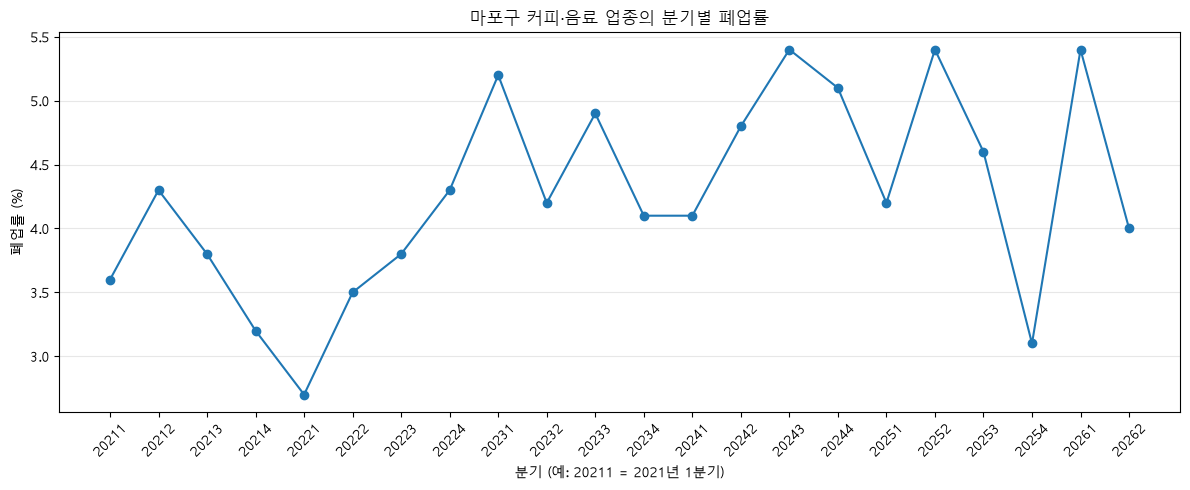

In [55]:
import matplotlib.pyplot as plt

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 분기 코드를 문자열로 바꿔 같은 간격으로 표시
quarter_labels = df_mapo_coffee["기준_년분기_코드"].astype(str)

plt.figure(figsize=(12, 5))

plt.plot(
    quarter_labels,
    df_mapo_coffee["폐업_률"],
    marker="o"
)

plt.title("마포구 커피·음료 업종의 분기별 폐업률")
plt.xlabel("분기 (예: 20211 = 2021년 1분기)")
plt.ylabel("폐업률 (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 마포구 커피·음료 업종의 폐업률 추이

- 2022년 1분기 폐업률이 2.7%로 가장 낮았다.
- 최고 폐업률은 5.4%로, 세 분기에서 관측됐다.
- 2026년 2분기는 전 분기보다 1.4%포인트 하락한 4.0%였다.
- 분기별 변동이 있으며, 이 그래프만으로 변화의 원인은 판단할 수 없다.

### 2-2. 같은 분기·업종의 자치구별 비교

In [56]:
# 가장 최근 분기 찾기
latest_quarter = df_coffee["기준_년분기_코드"].max()

# 해당 분기만 선택하고 폐업률이 높은 순으로 정렬
df_coffee_latest = df_coffee.loc[
    df_coffee["기준_년분기_코드"] == latest_quarter
].copy()

df_coffee_latest = df_coffee_latest.sort_values(
    "폐업_률", ascending=False
)

print("비교 분기:", latest_quarter)

df_coffee_latest[[
    "자치구_코드_명",
    "전체_점포_수",
    "폐업_점포_수",
    "폐업_률"
]]

비교 분기: 20262


,자치구_코드_명,전체_점포_수,폐업_점포_수,폐업_률
1885,중랑구,642.0,37.0,5.8
490,관악구,908.0,49.0,5.4
2085,광진구,971.0,48.0,4.9
789,금천구,662.0,32.0,4.8
1586,도봉구,429.0,20.0,4.7
989,강서구,1268.0,52.0,4.1
1487,노원구,798.0,33.0,4.1
1188,마포구,2306.0,93.0,4.0
1388,은평구,767.0,31.0,4.0
190,송파구,1613.0,61.0,3.8


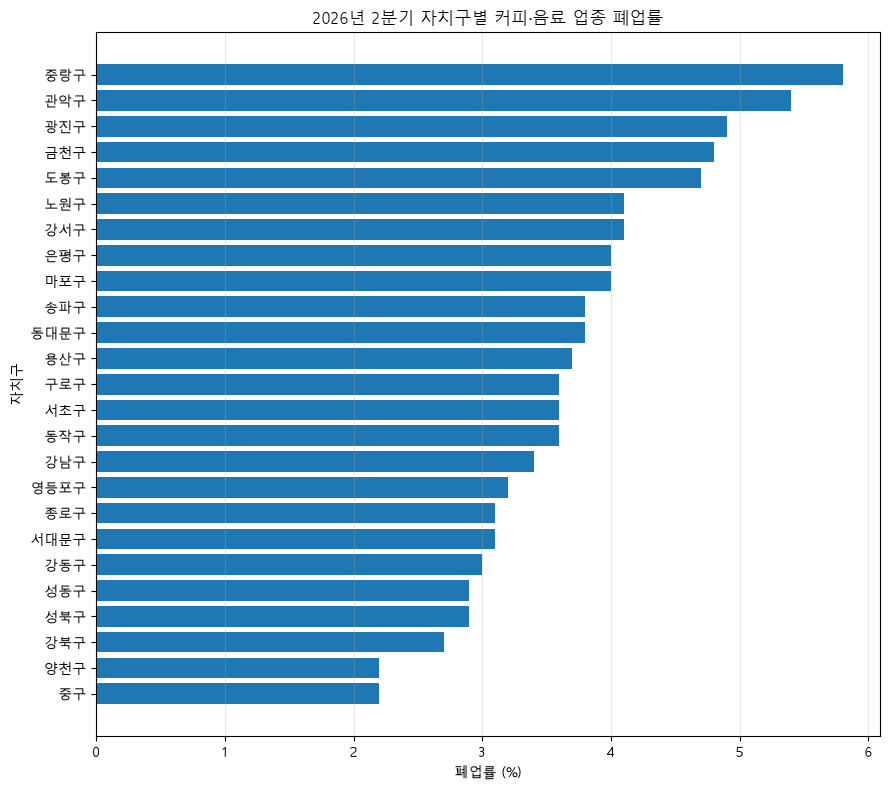

In [57]:
# 낮은 값부터 정렬하면 높은 값이 그래프 위쪽에 표시돼요.
plot_data = df_coffee_latest.sort_values("폐업_률")

plt.figure(figsize=(9, 8))

plt.barh(
    plot_data["자치구_코드_명"],
    plot_data["폐업_률"]
)

plt.title("2026년 2분기 자치구별 커피·음료 업종 폐업률")
plt.xlabel("폐업률 (%)")
plt.ylabel("자치구")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 2-3. 같은 분기·자치구의 업종별 비교

In [ ]:
# 전체 자료에서 최신 분기 확인
latest_quarter = df["기준_년분기_코드"].max()

# 최신 분기 + 마포구 + 점포 수가 1개 이상인 기록 선택
df_mapo_latest = df.loc[
    (df["기준_년분기_코드"] == latest_quarter)
    & (df["자치구_코드_명"] == "마포구")
    & (df["전체_점포_수"] > 0)
].copy()



In [59]:
# 1. 폐업률이 높은 순서로 정렬
sorted_data = df_mapo_latest.sort_values(
    "폐업_률", ascending=False
)

# 2. 위에서 10개 선택
top10 = sorted_data.head(10)

# 3. 필요한 열만 선택
result = top10[[
    "서비스_업종_코드_명",
    "전체_점포_수",
    "폐업_점포_수",
    "폐업_률"
]]

# 4. 결과 확인
result

,서비스_업종_코드_명,전체_점포_수,폐업_점포_수,폐업_률
1142,의류임대,26.0,3.0,11.5
1129,한복점,11.0,1.0,9.1
1101,재생용품 판매점,45.0,3.0,6.7
1136,주류도매,34.0,2.0,5.9
1195,일식음식점,609.0,32.0,5.3
1190,분식전문점,622.0,31.0,5.0
1194,양식음식점,837.0,41.0,4.9
1183,스포츠 강습,472.0,23.0,4.9
1135,미곡판매,71.0,3.0,4.2
1188,커피-음료,2306.0,93.0,4.0


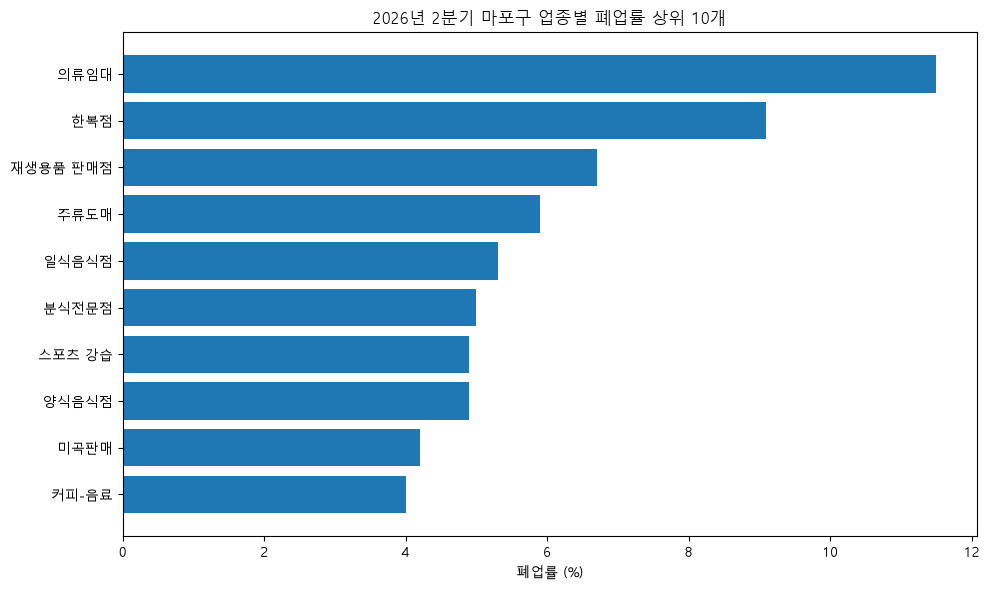

In [60]:
# 높은 폐업률이 그래프 위쪽에 나오도록 정렬
graph_data = top10.sort_values("폐업_률")

# 그래프 크기 설정
plt.figure(figsize=(10, 6))

# 가로 막대그래프
plt.barh(
    graph_data["서비스_업종_코드_명"],
    graph_data["폐업_률"]
)

plt.title("2026년 2분기 마포구 업종별 폐업률 상위 10개")
plt.xlabel("폐업률 (%)")

plt.tight_layout()
plt.show()


2026년 2분기 마포구에서 폐업률이 가장 높은 업종은 의류임대였다. 전체 점포 26개 중 폐업 수가 3개로, 폐업률은 11.5%였다. 점포 수가 적으면 몇 개의 폐업만으로도 비율이 높아질 수 있어 점포 수와 폐업 건수를 함께 확인해야 한다.

### 2-4. 숫자 변수의 상관관계

여기의 점포 수 0 제외는 폐업률을 포함한 EDA에만 적용한다. 모델 학습용 원본에는 적용하지 않는다.

In [61]:
# 전체 점포 수가 1개 이상인 행만 복사
df_rate = df.loc[df["전체_점포_수"] > 0].copy()

print(df_rate.shape)

(54755, 12)


In [62]:
# 비교할 숫자 열 선택
number_data = df_rate[[
    "전체_점포_수",
    "개업_점포_수",
    "폐업_점포_수",
    "폐업_률"
]]

# 상관관계 계산
correlation = number_data.corr()

correlation

,전체_점포_수,개업_점포_수,폐업_점포_수,폐업_률
전체_점포_수,1.000000,0.748721,0.883551,0.023426
개업_점포_수,0.748721,1.000000,0.808298,0.068251
폐업_점포_수,0.883551,0.808298,1.000000,0.135876
폐업_률,0.023426,0.068251,0.135876,1.000000


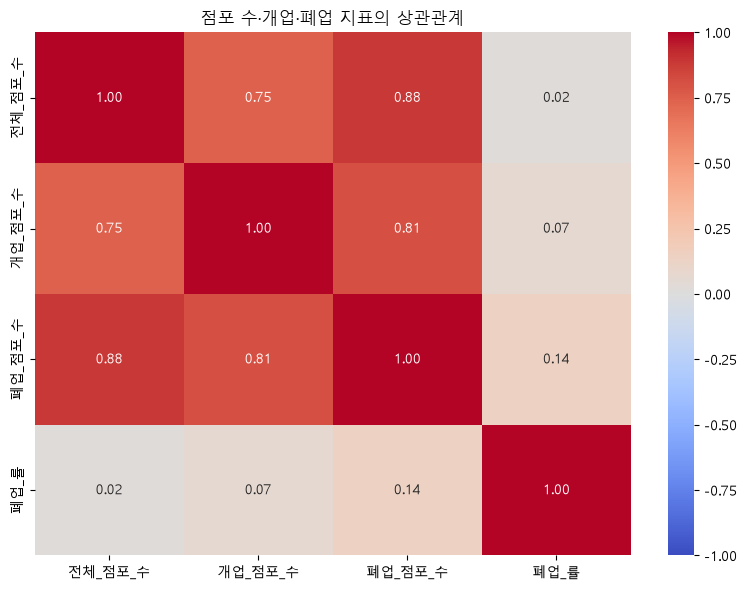

In [63]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("점포 수·개업·폐업 지표의 상관관계")
plt.tight_layout()
plt.show()

전체 점포 수와 폐업 점포 수의 상관계수는 약 0.84로, 점포 수가 많을수록 폐업 건수도 많은 경향이 나타났다. 반면 전체 점포 수와 폐업률의 상관계수는 약 0.02로, 뚜렷한 직선 관계는 나타나지 않았다.

## 3. 데이터 전처리

**이 구간이 전처리 부분이다.** CSV를 예측 모델이 학습할 수 있는 형태로 준비한다.

1. 원본을 복사하고 같은 자치구·업종의 기록을 분기순으로 정렬한다.
2. 연도·분기와 분기번호를 만든다.
3. 같은 자치구·업종의 다음 기록에서 분기번호와 폐업 수를 가져온다.
4. 분기 차이가 1인 기록만 남겨 중간 분기가 빠진 연결을 제외한다.
5. 다음 분기 폐업 수를 정답으로 사용한다. 미래의 값은 입력 변수에 넣지 않는다.

최종 입력은 숫자 4개이므로 문자 인코딩을 하지 않는다. 랜덤포레스트에는 표준화가 필수는 아니다.

### 3-1. 정렬과 분기 변수 생성

In [64]:
# 원본 데이터를 복사
model_data = df.copy()

# 자치구 → 업종 → 분기 순서로 정렬
model_data = model_data.sort_values([
    "자치구_코드",
    "서비스_업종_코드",
    "기준_년분기_코드"
])

# 정렬 결과 확인
model_data[[
    "자치구_코드_명",
    "서비스_업종_코드_명",
    "기준_년분기_코드",
    "폐업_점포_수"
]].head(10)

,자치구_코드_명,서비스_업종_코드_명,기준_년분기_코드,폐업_률
54764,종로구,한식음식점,20211,2.5
52275,종로구,한식음식점,20212,3.2
49787,종로구,한식음식점,20213,3.4
47300,종로구,한식음식점,20214,2.7
44813,종로구,한식음식점,20221,2.4
42325,종로구,한식음식점,20222,1.4
39838,종로구,한식음식점,20223,3.7
37351,종로구,한식음식점,20224,3.2
34864,종로구,한식음식점,20231,3.1
32378,종로구,한식음식점,20232,2.7


In [65]:
# 분기 코드에서 연도 추출
model_data["연도"] = model_data["기준_년분기_코드"] // 10

# 분기 코드에서 분기 추출
model_data["분기"] = model_data["기준_년분기_코드"] % 10

# 다음 분기마다 1씩 증가하는 번호 생성
model_data["분기번호"] = model_data["연도"] * 4 + model_data["분기"]

# 결과 확인
model_data[[
    "기준_년분기_코드",
    "연도",
    "분기",
    "분기번호"
]].head(6)

,기준_년분기_코드,연도,분기,분기번호
54764,20211,2021,1,8085
52275,20212,2021,2,8086
49787,20213,2021,3,8087
47300,20214,2021,4,8088
44813,20221,2022,1,8089
42325,20222,2022,2,8090


### 3-2. 다음 분기 정답 연결과 누락 분기 확인

groupby는 같은 지역·업종끼리 묶고, shift(-1)은 다음 기록의 값을 가져온다. 다음 기록이 반드시 다음 분기는 아니므로 분기 차이를 검사한다.

In [ ]:
# 같은 자치구·업종끼리 묶기
groups = model_data.groupby(["자치구_코드", "서비스_업종_코드"])

# 다음 기록의 분기번호와 폐업 수 가져오기
model_data["다음_분기번호"] = groups["분기번호"].shift(-1)
model_data["다음_폐업_점포_수"] = groups["폐업_점포_수"].shift(-1)


In [67]:
# 다음 기록과 현재 기록의 분기 차이 계산
model_data["분기차이"] = (
    model_data["다음_분기번호"] - model_data["분기번호"]
)

# 차이별 기록 수 확인
model_data["분기차이"].value_counts(dropna=False)

분기차이
1.0     52260
NaN      2498
3.0         1
17.0        1
14.0        1
8.0         1
11.0        1
9.0         1
12.0        1
Name: count, dtype: int64

In [ ]:
# 바로 다음 분기가 연결된 기록만 선택
count_data = model_data.loc[model_data["분기차이"] == 1].copy()

print("학습용 기록 수:", len(count_data))
count_data[["자치구_코드_명", "서비스_업종_코드_명", "기준_년분기_코드", "폐업_점포_수", "다음_폐업_점포_수"]].head()


## 4. 시간순 데이터 분할 및 입력·정답 준비

정답 시점 기준으로 2024년까지 학습, 2025년 검증, 2026년 1~2분기 테스트로 나눈다. 검증 자료로 모델을 선택하고 테스트는 최종 평가에 사용한다. 각 예측은 이전 분기까지의 실제 정보가 주어진 한 분기 앞 예측이다. 자료 공개 지연은 별도로 검토해야 한다.

입력 X: 전체 점포 수, 개업 점포 수, 폐업 점포 수, 분기.
정답 y: 같은 자치구·업종의 다음 분기 폐업 점포 수. 지역·업종은 기록을 묶는 데 사용하며 최종 모델 입력에는 포함하지 않는다.

In [90]:
# 다음 분기가 속한 연도
count_data["정답_연도"] = (
    count_data["다음_분기번호"] - 1
) // 4

# 학습: 정답이 2024년까지인 기록
count_train = count_data.loc[
    count_data["정답_연도"] <= 2024
].copy()

# 검증: 정답이 2025년인 기록
count_valid = count_data.loc[
    count_data["정답_연도"] == 2025
].copy()

# 테스트: 정답이 2026년인 기록
count_test = count_data.loc[
    count_data["정답_연도"] == 2026
].copy()

print("학습:", len(count_train))
print("검증:", len(count_valid))
print("테스트:", len(count_test))

print("합계:", len(count_train) + len(count_valid) + len(count_test))
print("전체:", len(count_data))

학습: 37298
검증: 9972
테스트: 4990
합계: 52260
전체: 52260


In [91]:
# 예측에 사용할 이번 분기 정보
count_features = [
    "전체_점포_수",
    "개업_점포_수",
    "폐업_점포_수",
    "분기"
]

# 학습 데이터
X_count_train = count_train[count_features]
y_count_train = count_train["다음_폐업_점포_수"]

# 검증 데이터
X_count_valid = count_valid[count_features]
y_count_valid = count_valid["다음_폐업_점포_수"]

# 테스트 데이터
X_count_test = count_test[count_features]
y_count_test = count_test["다음_폐업_점포_수"]

# 크기 확인
print("학습:", X_count_train.shape, y_count_train.shape)
print("검증:", X_count_valid.shape, y_count_valid.shape)
print("테스트:", X_count_test.shape, y_count_test.shape)

학습: (37298, 4) (37298,)
검증: (9972, 4) (9972,)
테스트: (4990, 4) (4990,)


## 5. 기준 예측 및 모델 학습·검증

MAE를 주 지표로, RMSE와 R²를 보조 지표로 비교한다. MAE·RMSE 단위는 개이며 R²는 정확도 백분율이 아니다.

### 5-1. 기준 예측
이번 분기 폐업 수가 다음 분기에도 유지된다고 예측한다.

In [92]:
import numpy as np

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# 이번 분기 폐업 수를 그대로 예측값으로 사용
count_baseline_pred = X_count_valid["폐업_점포_수"]

# MAE 계산
count_baseline_mae = mean_absolute_error(
    y_count_valid, count_baseline_pred
)

# RMSE 계산
count_baseline_mse = mean_squared_error(
    y_count_valid, count_baseline_pred
)
count_baseline_rmse = np.sqrt(count_baseline_mse)

# R² 계산
count_baseline_r2 = r2_score(
    y_count_valid, count_baseline_pred
)

print("기준 MAE:", round(count_baseline_mae, 3))
print("기준 RMSE:", round(count_baseline_rmse, 3))
print("기준 R²:", round(count_baseline_r2, 3))

기준 MAE: 2.625
기준 RMSE: 5.518
기준 R²: 0.868


### 5-2. 선형회귀

In [93]:
from sklearn.linear_model import LinearRegression

# 모델 생성
count_linear = LinearRegression()

# 학습
count_linear.fit(X_count_train, y_count_train)

# 검증 자료 예측
count_linear_pred = count_linear.predict(X_count_valid)

# MAE 계산
count_linear_mae = mean_absolute_error(
    y_count_valid, count_linear_pred
)

# RMSE 계산
count_linear_mse = mean_squared_error(
    y_count_valid, count_linear_pred
)
count_linear_rmse = np.sqrt(count_linear_mse)

# R² 계산
count_linear_r2 = r2_score(
    y_count_valid, count_linear_pred
)

print("선형회귀 MAE:", round(count_linear_mae, 3))
print("선형회귀 RMSE:", round(count_linear_rmse, 3))
print("선형회귀 R²:", round(count_linear_r2, 3))


선형회귀 MAE: 2.296
선형회귀 RMSE: 5.03
선형회귀 R²: 0.89


### 5-3. 의사결정나무 회귀

In [94]:
from sklearn.tree import DecisionTreeRegressor

# 모델 생성
count_tree = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# 학습
count_tree.fit(X_count_train, y_count_train)

# 검증 자료 예측
count_tree_pred = count_tree.predict(X_count_valid)

# MAE 계산
count_tree_mae = mean_absolute_error(
    y_count_valid, count_tree_pred
)

# RMSE 계산
count_tree_mse = mean_squared_error(
    y_count_valid, count_tree_pred
)
count_tree_rmse = np.sqrt(count_tree_mse)

# R² 계산
count_tree_r2 = r2_score(
    y_count_valid, count_tree_pred
)

print("의사결정나무 MAE:", round(count_tree_mae, 3))
print("의사결정나무 RMSE:", round(count_tree_rmse, 3))
print("의사결정나무 R²:", round(count_tree_r2, 3))

의사결정나무 MAE: 2.459
의사결정나무 RMSE: 5.15
의사결정나무 R²: 0.885


### 5-4. 랜덤포레스트 회귀 — 깊이 5

In [95]:
from sklearn.ensemble import RandomForestRegressor

# 모델 생성
count_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# 학습
count_forest.fit(X_count_train, y_count_train)

# 검증 자료 예측
count_forest_pred = count_forest.predict(X_count_valid)

# MAE 계산
count_forest_mae = mean_absolute_error(
    y_count_valid, count_forest_pred
)

# RMSE 계산
count_forest_mse = mean_squared_error(
    y_count_valid, count_forest_pred
)
count_forest_rmse = np.sqrt(count_forest_mse)

# R² 계산
count_forest_r2 = r2_score(
    y_count_valid, count_forest_pred
)

print("랜덤포레스트 MAE:", round(count_forest_mae, 3))
print("랜덤포레스트 RMSE:", round(count_forest_rmse, 3))
print("랜덤포레스트 R²:", round(count_forest_r2, 3))

랜덤포레스트 MAE: 2.336
랜덤포레스트 RMSE: 4.772
랜덤포레스트 R²: 0.901


### 5-5. 랜덤포레스트 회귀 — 깊이 10

In [96]:
# 나무 깊이를 10으로 변경
count_forest_v2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

# 학습
count_forest_v2.fit(X_count_train, y_count_train)

# 학습·검증 자료 예측
count_train_pred_v2 = count_forest_v2.predict(X_count_train)
count_valid_pred_v2 = count_forest_v2.predict(X_count_valid)

# 학습 MAE
count_train_mae_v2 = mean_absolute_error(
    y_count_train, count_train_pred_v2
)

# 검증 성능
count_mae_v2 = mean_absolute_error(
    y_count_valid, count_valid_pred_v2
)

count_mse_v2 = mean_squared_error(
    y_count_valid, count_valid_pred_v2
)
count_rmse_v2 = np.sqrt(count_mse_v2)

count_r2_v2 = r2_score(
    y_count_valid, count_valid_pred_v2
)

print("학습 MAE:", round(count_train_mae_v2, 3))
print("검증 MAE:", round(count_mae_v2, 3))
print("검증 RMSE:", round(count_rmse_v2, 3))
print("검증 R²:", round(count_r2_v2, 3))

학습 MAE: 2.031
검증 MAE: 2.173
검증 RMSE: 4.451
검증 R²: 0.914


검증 MAE는 기준 2.625개, 선형회귀 2.296개, 의사결정나무 2.459개, 랜덤포레스트 깊이 5는 2.336개, 깊이 10은 2.173개였다. 비교한 설정 중 깊이 10의 랜덤포레스트가 MAE·RMSE 모두 가장 낮아 최종 모델로 선택했다. 테스트 결과를 보고 설정을 변경하지 않는다.

## 6. 최종 모델 테스트 평가

선택한 모델을 고정하고 2026년 1~2분기 4,990개 기록에서 평가한다.

In [97]:
# 선택한 모델로 테스트 자료 예측
count_test_pred = count_forest_v2.predict(X_count_test)

# 모델의 테스트 성능
count_test_mae = mean_absolute_error(
    y_count_test, count_test_pred
)

count_test_mse = mean_squared_error(
    y_count_test, count_test_pred
)
count_test_rmse = np.sqrt(count_test_mse)

count_test_r2 = r2_score(
    y_count_test, count_test_pred
)

# 같은 테스트 자료에서 기준 예측 평가
count_test_baseline = X_count_test["폐업_점포_수"]

count_test_baseline_mae = mean_absolute_error(
    y_count_test, count_test_baseline
)

print("테스트 MAE:", round(count_test_mae, 3))
print("테스트 RMSE:", round(count_test_rmse, 3))
print("테스트 R²:", round(count_test_r2, 3))
print("테스트 기준 MAE:", round(count_test_baseline_mae, 3))

테스트 MAE: 2.262
테스트 RMSE: 4.865
테스트 R²: 0.883
테스트 기준 MAE: 2.722


최종 후보인 랜덤포레스트 회귀 모델은 2026년 1~2분기 테스트 자료에서 MAE 2.262개, RMSE 4.865개, R² 0.883을 기록하였다. 이번 분기 폐업 수를 다음 분기 예측값으로 사용하는 기준 예측보다 MAE가 약 16.9% 감소하였다.

## 7. 예측 결과 시각화와 해석

### 7-1. 실제값과 예측값 비교

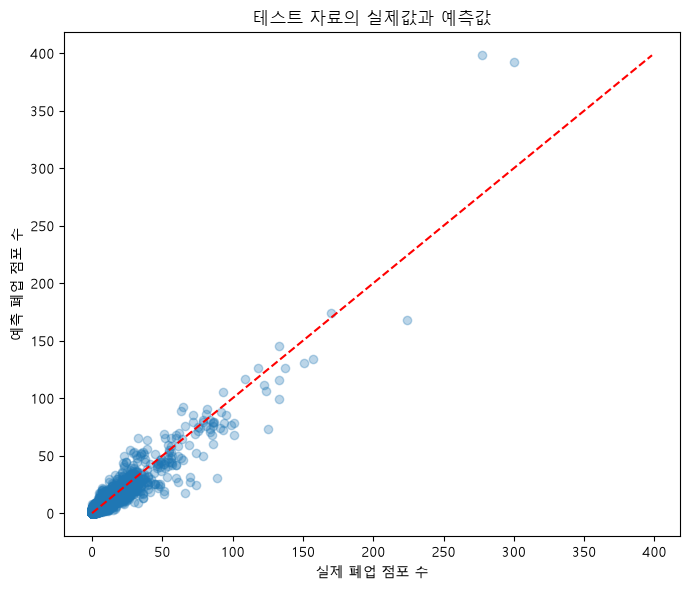

In [98]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_count_test,
    count_test_pred,
    alpha=0.3
)

# 실제값과 예측값이 같을 때의 기준선
line_max = max(y_count_test.max(), count_test_pred.max())

plt.plot(
    [0, line_max],
    [0, line_max],
    color="red",
    linestyle="--"
)

plt.xlabel("실제 폐업 점포 수")
plt.ylabel("예측 폐업 점포 수")
plt.title("테스트 자료의 실제값과 예측값")
plt.tight_layout()
plt.show()

테스트 자료의 실제값과 예측값은 전반적으로 함께 증가하는 경향을 보였다. 다만 일부 기록에서는 큰 과대·과소 예측이 나타났으며, 모든 지역·업종에서 동일한 수준으로 예측하는 것은 아니다.

### 7-2. 0~30개 구간 확대

표시 범위만 바꾸며 평가 기록은 삭제하지 않는다. 실제 건수는 정수이므로 같은 x좌표에 여러 예측값이 쌓일 수 있다.

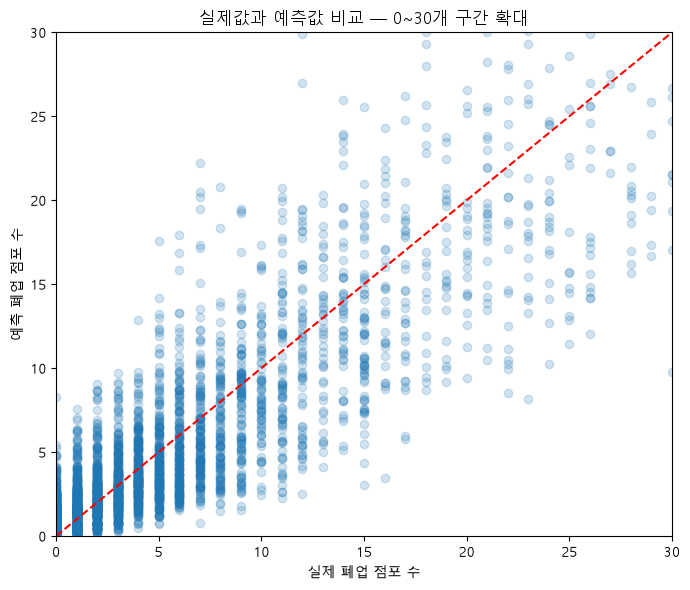

In [99]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_count_test,
    count_test_pred,
    alpha=0.2
)

plt.plot([0, 30], [0, 30], "r--")

# 표시 범위만 확대
plt.xlim(0, 30)
plt.ylim(0, 30)

plt.xlabel("실제 폐업 점포 수")
plt.ylabel("예측 폐업 점포 수")
plt.title("실제값과 예측값 비교 — 0~30개 구간 확대")
plt.tight_layout()
plt.show()

### 7-3. 입력 변수 중요도

학습 중 나무의 불순도 감소를 기준으로 계산한 중요도이며, 인과관계나 예측 정확도의 비율이 아니다.

In [102]:
# 최종 모델의 변수 중요도 가져오기
importance = count_forest_v2.feature_importances_

# 변수 이름과 중요도를 표로 정리
importance_data = pd.DataFrame({
    "변수": count_features,
    "중요도": importance
})

# 중요도가 높은 순서로 정렬
importance_data = importance_data.sort_values(
    "중요도", ascending=False
)

importance_data

,변수,중요도
2,폐업_점포_수,0.830957
0,전체_점포_수,0.123205
1,개업_점포_수,0.038195
3,분기,0.007643


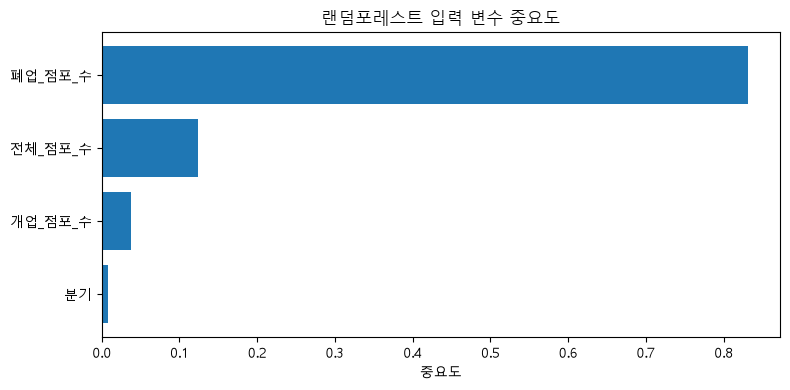

In [103]:
plt.figure(figsize=(8, 4))

plt.barh(
    importance_data["변수"],
    importance_data["중요도"]
)

# 중요도가 높은 변수를 위쪽에 표시
plt.gca().invert_yaxis()

plt.xlabel("중요도")
plt.title("랜덤포레스트 입력 변수 중요도")
plt.tight_layout()
plt.show()

랜덤포레스트의 변수 중요도는 현재 분기 폐업 점포 수가 가장 높았으며, 전체 점포 수, 개업 점포 수, 분기 순으로 나타났다. 이는 모델이 예측에 활용한 정도를 나타내며, 폐업의 원인을 의미하지 않는다.

## 8. 평가한 모델 저장

Streamlit에서는 저장된 모델을 불러온다. 앱에서도 학습과 같은 입력 열 이름·순서를 사용한다. 저장 경로는 프로젝트의 model 폴더로 통일한다.

In [ ]:
import os
import joblib

# 폴더가 없으면 생성
os.makedirs("model", exist_ok=True)

# 테스트 평가에 사용한 모델 저장
joblib.dump(count_forest_v2, "model/closure_count_model.joblib")
print("모델 저장 완료")


## 9. 한계 및 활용 범위

- 예측 단위는 지역·업종의 분기별 폐업 점포 수이며 개별 가게의 폐업 여부가 아니다.
- 점포 규모에 따라 오차의 의미가 다르고, 일부 기록은 과대·과소 예측이 크다.
- 자료의 집계 기준과 공개 시점에 따라 실제 활용 가능성을 검토해야 한다.
- 지역·업종 선택은 해당 숫자 기록을 불러오는 역할이며, 동일한 숫자 입력이면 같은 예측을 출력한다.
- 미래의 경제·정책 변화에 대한 성능은 보장하지 않는다.